# Shoreline change at Purakkad

Trying to see if we can identify coastal movements using satellite data. 

Measures how far the open coast at Purakkad moved between two periods of satellite imagery: Landsat from 1972 to 1974, and the JRC water record from 1984 to 2021.

Note that the Thanneermukkom barrage and the Idukki dam were both finished in 1976, so the two periods fall either side of the largest modern intervention in this system. 

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = pathlib.Path.cwd().parent

## 1. Two water masks

A pixel counts as water if it was water in most images of that period, not if it was wet on one day. Both periods are measured the same way, which is what makes them comparable.

Landsat stores raw sensor counts, so brightness shifts between images and no single cutoff works. Each image gets its own, taken from the gap between the two peaks of its histogram. Hazy images have no two peaks and are dropped.

In [3]:
from sat import landsat_mss as mss, water, shoreline

BBOX = [76.30, 9.20, 76.60, 9.55]   # Purakkad and its barrier spit
EARLY, LATE = '1972-76', '1984-2021'

frequency, meta = mss.water_extent(BBOX, 'pamba')
early = frequency > 0.6
print(f'{EARLY}: {meta["n_scenes"]} usable Landsat scenes')

gsw = water.surface_water(BBOX, shape=early.shape, layers=('occurrence',))
late = gsw['occurrence'] > 60
print(f'{LATE}: JRC record, {100*late.mean():.0f}% of the box is water')

1972-76: 10 usable Landsat scenes
1984-2021: JRC record, 22% of the box is water


## 2. Keep only the open sea

Inside the lagoon the two periods disagree about what counts as water, because the backwaters flood and drain seasonally and the two periods sample different years and months. No such issue in the open coast, so we keep that

In [4]:
sea = {EARLY: shoreline.open_sea(early), LATE: shoreline.open_sea(late)}
for label, mask in sea.items():
    print(f'{label:10s} open sea covers {100*mask.mean():.1f}% of the box')

1972-76    open sea covers 19.8% of the box
1984-2021  open sea covers 20.0% of the box


## 3. How precisely can we locate a shoreline?

Three sources of error, added in quadrature as the coastal change literature
does: the pixel size, which dominates; where inside that pixel the water
threshold actually falls; and how well the image sits on the ground.

In [5]:
NATIVE = {EARLY: 79.0, LATE: 30.0}   # metres per pixel, as flown
err = {k: shoreline.positional_error(v) for k, v in NATIVE.items()}
combined = np.hypot(err[EARLY], err[LATE])

for k, v in err.items():
    print(f'{k:10s} +/- {v:5.0f} m')
print(f'combined    +/- {combined:5.0f} m  <- movement smaller than this cannot be claimed')

1972-76    +/-    92 m
1984-2021  +/-    35 m
combined    +/-    99 m  <- movement smaller than this cannot be claimed


## 4. Measure the shoreline on every row

The coast here runs roughly north to south with the sea to the west, so each
raster row is a clean cross-shore transect and no gradient estimate is needed.
On each row we take the furthest-east sea pixel.

All images sit on one common grid, so column index converts to metres using
that grid's cell size. Using each sensor's native resolution here was an early
bug and produced apparent shifts of ten kilometres.

In [6]:
H, W = early.shape
grid_m = (BBOX[2] - BBOX[0]) * 111320 * np.cos(np.radians(9.375)) / W
print(f'common grid {W} x {H}, cell size {grid_m:.0f} m')

rows, _ = shoreline.compare(sea, NATIVE, grid_m, step=2)
shift = np.array([r[LATE] - r[EARLY] for r in rows])
lat = np.array([BBOX[3] - (r['row'] / H) * (BBOX[3] - BBOX[1]) for r in rows])
significant = np.abs(shift) > combined

print(f'{len(rows)} usable rows')
print(f'median movement {np.median(shift):+.0f} m')
print(f'{significant.sum()} of {len(rows)} exceed the combined error')

common grid 552 x 647, cell size 60 m
324 usable rows
median movement +0 m
119 of 324 exceed the combined error


## 5. Where did it move?

Broken down by latitude. Purakkad sits at about 9.36 N.

In [7]:
for lo, hi in [(9.20, 9.30), (9.30, 9.36), (9.36, 9.42), (9.42, 9.50), (9.50, 9.55)]:
    m = (lat >= lo) & (lat < hi)
    if m.sum():
        print(f'{lo:.2f}-{hi:.2f} N   n={m.sum():3d}   median {np.median(shift[m]):+6.0f} m   '
              f'{int((np.abs(shift[m]) > combined).sum()):3d} beyond error')

9.20-9.30 N   n= 92   median     +0 m     2 beyond error
9.30-9.36 N   n= 56   median    -60 m    27 beyond error
9.36-9.42 N   n= 55   median   +179 m    43 beyond error
9.42-9.50 N   n= 74   median    -60 m    20 beyond error
9.50-9.55 N   n= 46   median   +119 m    26 beyond error


## 6. The figure

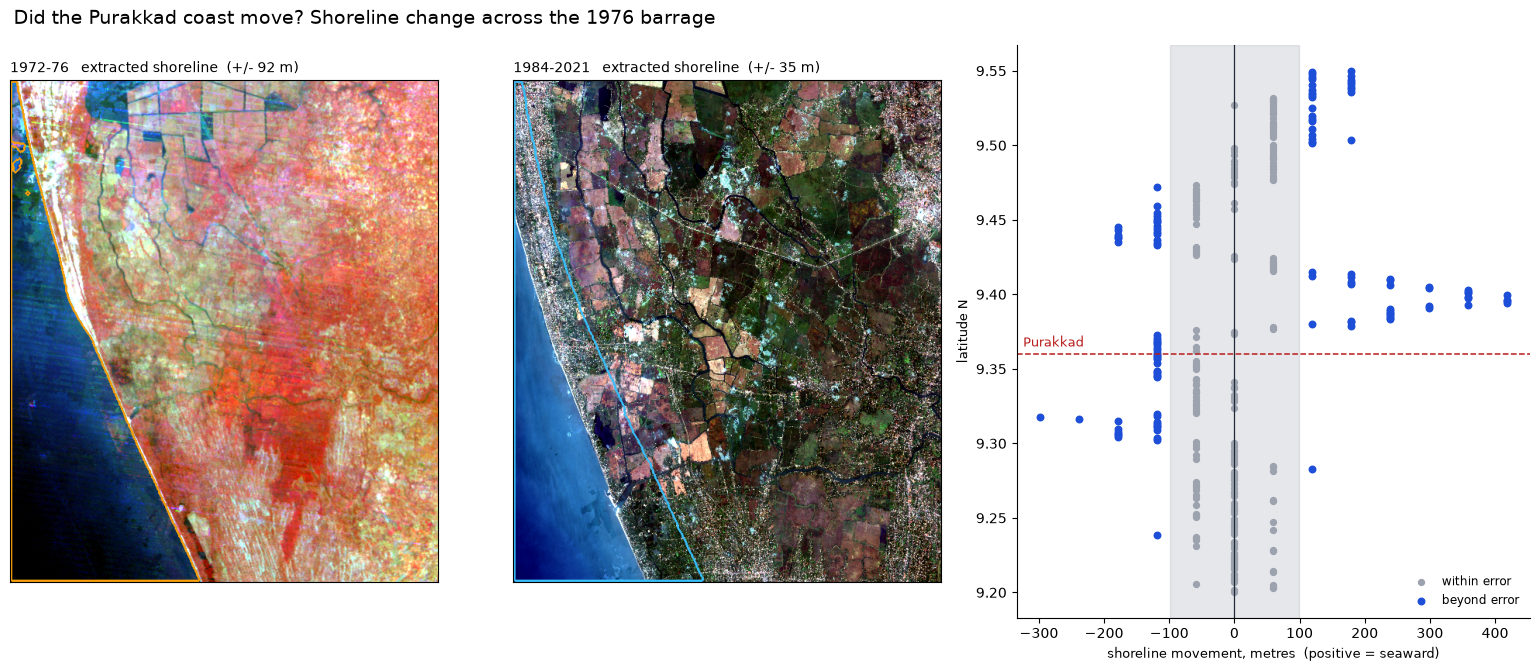

In [8]:
def stretch(a, lo=2, hi=98):
    v = a[np.isfinite(a)]
    p0, p1 = np.percentile(v, [lo, hi])
    return np.clip((a - p0) / (p1 - p0 + 1e-9), 0, 1)

from sat import stack
mss_bands = mss.composite(BBOX)
early_img = np.dstack([stretch(mss_bands[b]) for b in ('nir08', 'red', 'green')])

med, _, _ = stack.cached_composite('pamba', BBOX, '2022-01-01', '2024-12-31', 'dry')
zoom = np.array(early.shape) / np.array(med['red'].shape)
late_img = np.clip(np.dstack([ndimage.zoom(stretch(med[b]), zoom, order=1)
                              for b in ('red', 'green', 'blue')]), 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(15.5, 6.8), gridspec_kw={'width_ratios': [1, 1, 1.2]})
for a, (img, label, colour) in zip(ax[:2], [(early_img, EARLY, '#f59e0b'),
                                            (late_img, LATE, '#38bdf8')]):
    a.imshow(img)
    edge = ndimage.binary_dilation(shoreline.boundary(sea[label]), iterations=1)
    overlay = np.zeros((*edge.shape, 4))
    overlay[edge] = list(plt.matplotlib.colors.to_rgb(colour)) + [1.0]
    a.imshow(overlay)
    a.set_title(f'{label}   extracted shoreline  (+/- {err[label]:.0f} m)', fontsize=10, loc='left')
    a.set_xticks([]); a.set_yticks([])

ax[2].axvspan(-combined, combined, color='#9ca3af', alpha=.25)
ax[2].scatter(shift[~significant], lat[~significant], s=18, color='#9ca3af', label='within error')
ax[2].scatter(shift[significant], lat[significant], s=22, color='#1d4ed8', label='beyond error')
ax[2].axvline(0, color='#1f2937', lw=.9)
ax[2].axhline(9.36, color='#b91c1c', lw=1.1, ls='--')
ax[2].text(ax[2].get_xlim()[0] + 10, 9.365, 'Purakkad', fontsize=9, color='#b91c1c')
ax[2].set_xlabel('shoreline movement, metres  (positive = seaward)', fontsize=9.5)
ax[2].set_ylabel('latitude N', fontsize=9.5)
ax[2].legend(fontsize=8.5, frameon=False, loc='lower right')
ax[2].spines[['top', 'right']].set_visible(False)

fig.suptitle('Did the Purakkad coast move? Shoreline change across the 1976 barrage',
             fontsize=13.5, x=0.012, ha='left')
fig.tight_layout()
plt.show()

## Result

Stable overall, with a median movement of zero, but the movement that does
exceed the error is structured rather than scattered. Immediately north of
Purakkad, between 9.36 and 9.42 N, the shore advanced about 180 m in fifty
years.

Note that this is only 50 years of measured change (albeit with the dam changing the geography), and we want to reconstruct this going back a couple thousand years. 